# Choose a classification metric by the decision

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/firefly1248/demo-notebooks/blob/main/notebooks/classification_metrics/classification_metrics_by_decision.ipynb)

A metric is worth reading only if it answers the question that the decision asks of the model.
Each section takes one decision and shows which metric answers it and which one misleads.

The running example is card fraud with analyst review: 100,000 card transactions a day, 0.5% of
them fraudulent. An analyst reviews a flagged transaction and stops it if it is fraud. A stopped
fraud saves $V = 200$ on average, and a review costs $c = 5$ whether or not the transaction is
fraud, so the profit of a flagged set is $V \times \text{frauds in it} - c \times \text{its size}$.
Two simplifications: the analyst always recognizes fraud when reviewing, and a legitimate
transaction flagged by mistake costs only the review, with no friction for the customer. Every
count in the tables is transactions per day (customers in Section 8).

Scores come from an equal-variance binormal model (except model A in Section 5 and the segments in
Section 8): legitimate transactions score $N(0, 1)$, fraudulent ones $N(d, 1)$. Its ROC AUC is
$\Phi(d / \sqrt{2})$, so a target ROC AUC $A$ gives $d = \sqrt{2}\,\Phi^{-1}(A)$. Under this model the working points (TPR, FPR, precision and profit at
a threshold) have closed forms. The notebook computes them analytically and checks them against a
simulated day of transactions; the article quotes the analytical value wherever the notebook
computes one.

Each simulated section ends with a summary table holding the numbers the article uses; the last
cells check them against the article.

In [1]:
import json
import textwrap
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy.optimize import brentq
from scipy.special import expit, logit
from scipy.stats import norm
from sklearn.metrics import (average_precision_score, brier_score_loss, log_loss,
                             roc_auc_score)

T0 = time.perf_counter()
rng = np.random.default_rng(42)
N = 100_000                  # transactions per day
V, COST = 200, 5             # saved per stopped fraud, cost of one review
T_BAYES = COST / V           # review when p > c / V
PREFIX = "classification_metrics_"  # figures and results are written next to the notebook
RESULTS, CHECKS = {}, []
print({m.__name__: m.__version__ for m in (np, scipy, sklearn, pd, matplotlib)})

plt.rcParams.update({
    "font.size": 14, "axes.labelsize": 16, "xtick.labelsize": 14, "ytick.labelsize": 14,
    "legend.fontsize": 14, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False, "savefig.dpi": 200,
})

{'numpy': '2.4.6', 'scipy': '1.18.1', 'sklearn': '1.9.0', 'pandas': '3.0.5', 'matplotlib': '3.11.1'}


### Definitions

- **PR AUC** is scikit-learn's `average_precision_score`: precision averaged over the recall levels
  of the observed positives.
- **ECE** (expected calibration error): 15 equal-width bins over $[0, 1]$; in each bin, the absolute
  gap between the mean prediction and the observed rate, weighted by the share of transactions in
  the bin. Other binning choices give other values; this one is fixed for the whole notebook.
- A threshold rule flags every transaction whose score is at or above the threshold for review.
  Recall is TPR: the share of frauds caught.
- In the summary tables, rows or columns named "analytic" or without a suffix come from the
  binormal model, and those named or suffixed "sim" are computed on the simulated transactions. The
  exception: ROC AUC, PR AUC, Brier, log loss and ECE in Sections 1, 2 and 8 are always computed on
  the simulated data.
- With a few hundred positives, a simulated PR AUC moves by a few hundredths between draws, so it
  can sit visibly away from the analytic value.

In [2]:
def d_for_auc(auc):
    # Binormal separation that gives this ROC AUC.
    return np.sqrt(2) * norm.ppf(auc)


def simulate_binormal(n_pos, d):
    # Labels and scores for N transactions, the first n_pos of them positive.
    y = np.r_[np.ones(n_pos, dtype=int), np.zeros(N - n_pos, dtype=int)]
    s = np.r_[rng.normal(d, 1, n_pos), rng.normal(0, 1, N - n_pos)]
    return y, s


def posterior(s, d, prior):
    # P(positive | score) under the binormal model with this prior.
    return expit(logit(prior) + d * s - d**2 / 2)


def score_at_posterior(p, d, prior):
    # The score at which the posterior equals p.
    return (logit(p) - logit(prior) + d**2 / 2) / d


def bin_index(p, bins=15):
    # Equal-width bins over [0, 1]; p = 1 goes to the last bin.
    return np.minimum((p * bins).astype(int), bins - 1)


def ece(y, p, bins=15):
    b = bin_index(p, bins)
    return np.abs(np.bincount(b, y, bins) - np.bincount(b, p, bins)).sum() / len(y)


def value_metrics(y, p):
    return {"ROC AUC": roc_auc_score(y, p), "PR AUC": average_precision_score(y, p),
            "Brier": brier_score_loss(y, p), "log loss": log_loss(y, p), "ECE": ece(y, p)}


def counts(tp, fp, n_pos, cost):
    # Rates, counts and profit of a flagged set with tp frauds and fp legitimate transactions.
    return {"recall": tp / n_pos, "FPR": fp / (N - n_pos), "caught": tp, "false alarms": fp,
            "reviews": tp + fp, "precision": tp / (tp + fp), "F1": 2 * tp / (tp + fp + n_pos),
            "profit": V * tp - cost * (tp + fp)}


# Analytic side: a model is a pair of functions tpr(t), fpr(t) of the threshold t on the score.
def binormal(d):
    return (lambda t: norm.sf(t - d)), norm.sf


def point(t, tpr, fpr, n_pos, cost=COST):
    # Expected counts when every transaction scoring above t is reviewed.
    return counts(n_pos * tpr(t), (N - n_pos) * fpr(t), n_pos, cost)


def solve(f, target):
    # Threshold at which the decreasing function f equals target.
    return brentq(lambda t: f(t) - target, -20, 20)


def at_recall(r, tpr, fpr, n_pos, cost=COST):
    return point(solve(tpr, r), tpr, fpr, n_pos, cost)


def at_reviews(k, tpr, fpr, n_pos):
    return point(solve(lambda t: n_pos * tpr(t) + (N - n_pos) * fpr(t), k), tpr, fpr, n_pos)


def max_profit(d, n_pos, cost=COST):
    # Profit-maximizing point of a binormal model: review when the posterior exceeds c / V.
    return point(score_at_posterior(cost / V, d, n_pos / N), *binormal(d), n_pos, cost)


GRID = np.linspace(-10, 15, 250_001)


def pr_summary(tpr, fpr, n_pos):
    # Best-F1 point and PR AUC (precision integrated over recall) of the expected PR curve.
    pts = point(GRID, tpr, fpr, n_pos)
    i = np.argmax(pts["F1"])
    pr_auc = np.sum(pts["precision"][1:] * -np.diff(pts["recall"]))
    return {k: v[i] for k, v in pts.items()}, pr_auc


# Simulation side.
def sim_point(y, s, t, cost=COST):
    flagged = s >= t
    tp = np.sum(flagged & (y == 1))
    return counts(tp, flagged.sum() - tp, y.sum(), cost)


def sim_at_recall(y, s, r, cost=COST):
    pos = np.sort(s[y == 1])[::-1]
    return sim_point(y, s, pos[int(np.ceil(r * len(pos))) - 1], cost)


def sim_top(y, s):
    # Frauds among the k highest scores, for k = 1..N.
    return np.cumsum(y[np.argsort(-s)])


def sim_best_f1(y, s):
    # The top-k set with the highest F1 over all k.
    tp = sim_top(y, s)
    k = np.arange(1, len(y) + 1)
    pts = counts(tp, k - tp, y.sum(), COST)
    i = np.argmax(pts["F1"])
    return {name: v[i] for name, v in pts.items()}


def sim_max_profit(y, s, d, cost=COST):
    # The simulated day at the analytic profit-maximizing rule: posterior above c / V.
    return sim_point(y, s, score_at_posterior(cost / V, d, y.sum() / N), cost)


# Reporting.
def report(key, table, digits):
    # Round each column the way the article does (0 digits: a whole count), print, store.
    table = table.round(digits).astype({c: int for c, n in digits.items() if n == 0})
    RESULTS[key] = table.to_dict("index")
    print(table.to_string())


def check(name, value, expected, kind):
    # kind: "count" within 2% relative, "rate" within 0.01 absolute, "close" within 0.001 absolute,
    # "exact" up to float rounding.
    CHECKS.append({"check": name, "value": value, "expected": expected, "kind": kind})


def save(fig, name):
    fig.savefig(f"{PREFIX}{name}.png")
    plt.show()


POINT_DIGITS = {"recall": 2, "FPR": 4, "caught": 0, "false alarms": 0, "reviews": 0,
                "precision": 3, "F1": 2, "profit": 0}

### The fraud model

500 frauds and 99,500 legitimate transactions, ROC AUC 0.97, scores turned into the exact
posterior probability of fraud. Sections 1, 2, 3 and 7 use this day.

In [3]:
RATE, AUC = 0.005, 0.97
dF = d_for_auc(AUC)
nF = round(RATE * N)
nF_neg = N - nF
yF, sF = simulate_binormal(nF, dF)
pF = posterior(sF, dF, RATE)
tprF, fprF = binormal(dF)
print(f"d = {dF:.4f}, frauds = {nF:,}, simulated ROC AUC = {roc_auc_score(yF, sF):.4f}")
print(f"Review everything: profit {V * nF - COST * N:,}; review nothing: profit 0")

d = 2.6598, frauds = 500, simulated ROC AUC = 0.9725
Review everything: profit -400,000; review nothing: profit 0


## 1. What each metric sees

**Decision:** none yet; each later section takes one.

**What the model must provide:** depends on the decision: an order of transactions, or
probabilities that are right in value. This section shows which of the two each metric sees.

- **ROC AUC and PR AUC** read only the order of the scores. Any increasing transform leaves them
  unchanged, so they cannot tell a calibrated probability from a distorted one.
- **Brier score, log loss and ECE** read the values, and change when the values change even if the
  order does not.
- **ECE alone misleads too:** a constant prediction equal to the base rate is perfectly
  calibrated, so its ECE is near zero, yet it ranks nothing and its ROC AUC is 0.5.

Two increasing transforms of the calibrated probabilities, $p \mapsto p^2$ and
$p \mapsto 0.5\,p$, and the constant prediction 0.005:

In [4]:
variants = {"calibrated p": pF, "p ** 2": pF**2, "0.5 * p": 0.5 * pF,
            "constant 0.005": np.full(N, RATE)}
tab1 = pd.DataFrame({k: value_metrics(yF, v) for k, v in variants.items()}).T

rank = ["ROC AUC", "PR AUC"]
shift = (tab1.loc[["p ** 2", "0.5 * p"], rank] - tab1.loc["calibrated p", rank]).abs().to_numpy().max()
print(f"Largest change in ROC AUC or PR AUC under the two transforms: {shift:.1e}\n")
check("S1 ROC AUC and PR AUC unchanged by p**2 and 0.5*p", shift, 0.0, "exact")
check("S1 constant prediction: ECE", tab1.loc["constant 0.005", "ECE"], 0.0, "exact")
check("S1 constant prediction: ROC AUC", tab1.loc["constant 0.005", "ROC AUC"], 0.5, "rate")

report("s1_what_each_metric_sees", tab1,
       {"ROC AUC": 3, "PR AUC": 3, "Brier": 5, "log loss": 4, "ECE": 4})

Largest change in ROC AUC or PR AUC under the two transforms: 0.0e+00

                ROC AUC  PR AUC    Brier  log loss     ECE
calibrated p      0.972   0.417  0.00364    0.0158  0.0004
p ** 2            0.972   0.417  0.00399    0.0242  0.0036
0.5 * p           0.972   0.417  0.00397    0.0171  0.0025
constant 0.005    0.500   0.005  0.00497    0.0315  0.0000


## 2. Probabilities: expected value

**Decision:** review a transaction when the expected gain of the review is positive. The expected
gain is $pV - c$, so the rule is to review when $p > c / V = 5 / 200 = 0.025$.

**What the model must provide:** probabilities that are right in value, not only in order, because
the rule compares $p$ with a fixed number.

**What answers it:** Brier score and log loss (proper scoring rules), ECE as a diagnostic, and the
profit at the threshold $c / V$ itself. **What misleads:** ROC AUC and PR AUC, which cannot see
calibration.

Model **C** returns the exact posterior under the binormal model with prior 0.005. Model **M** is an
increasing transform of C, so it ranks the same transactions in the same order: it computes the
posterior as if the prior were 0.5, which is what a model trained with balanced class weights, or
on data oversampled to balance the classes by duplicating frauds, returns when nobody corrects it.

Because M's error is a prior shift, it has an exact fix: M at the threshold
$t_M = \operatorname{expit}(\operatorname{logit}(0.025) - \operatorname{logit}(0.005) +
\operatorname{logit}(0.5))$ selects the same transactions as C at 0.025. The miscalibration costs
money only when M's probabilities are used as they come.

The profit curve is flat near its top, so in one simulated day the best threshold on the grid can
land a little away from 0.025 while the profit at 0.025 stays within a few hundred of the maximum.

The reliability diagram uses the ECE bins and leaves out bins with fewer than 50 transactions,
where the observed rate is noise. C's drawn bins above about 0.13 hold only a few dozen frauds
each, so its wiggle around the diagonal is sampling noise; it has no well-filled bins above about
0.4.

In [5]:
PRIORS2 = {"C": RATE, "M": 0.5}
probs2 = {m: posterior(sF, dF, prior) for m, prior in PRIORS2.items()}
THR_M = expit(logit(T_BAYES) - logit(RATE) + logit(0.5))
print(f"Equivalent threshold for M: {THR_M:.4f}")
RESULTS["s2_threshold_M"] = round(THR_M, 4)

rows = {}
for label, m, thr in [("C, p > 0.025", "C", T_BAYES), ("M, p > 0.025", "M", T_BAYES),
                      (f"M, p > {THR_M:.2f}", "M", THR_M)]:
    p = probs2[m]
    a = point(score_at_posterior(thr, dF, PRIORS2[m]), tprF, fprF, nF)
    b = sim_point(yF, p, thr)
    rows[label] = {**value_metrics(yF, p), "reviews": a["reviews"], "caught": a["caught"],
                   "profit": a["profit"], "reviews sim": b["reviews"], "caught sim": b["caught"],
                   "profit sim": b["profit"]}
tab2 = pd.DataFrame(rows).T
row_c, row_m, row_mt = tab2.index
for col in ["ROC AUC", "PR AUC"]:
    check(f"S2 {col} identical for C and M", abs(tab2.loc[row_c, col] - tab2.loc[row_m, col]), 0.0, "exact")

same = np.array_equal(probs2["C"] >= T_BAYES, probs2["M"] >= THR_M)
print(f"M at {THR_M:.4f} selects exactly the transactions C selects at 0.025: {same}")
assert same
check("S2 transactions selected by only one of M at thr_M and C at 0.025",
      np.sum((probs2["C"] >= T_BAYES) != (probs2["M"] >= THR_M)), 0, "exact")
check("S2 M at thr_M: analytic profit equals C's", tab2.loc[row_mt, "profit"], tab2.loc[row_c, "profit"], "exact")

for row, reviews, caught, profit in [(row_c, 2972, 382, 61479), (row_m, 52131, 498, -160992)]:
    check(f"S2 {row}: reviews", tab2.loc[row, "reviews"], reviews, "count")
    check(f"S2 {row}: caught", tab2.loc[row, "caught"], caught, "count")
    check(f"S2 {row}: profit", tab2.loc[row, "profit"], profit, "count")

# Profit of model C over a grid of thresholds: expected (analytic) and simulated.
grid = np.round(np.arange(0.005, 0.2001, 0.0025), 4)
a = point(score_at_posterior(grid, dF, RATE), tprF, fprF, nF)
sweep = pd.DataFrame({"threshold": grid, "profit": a["profit"],
                      "profit sim": [sim_point(yF, probs2["C"], t)["profit"] for t in grid]}
                     ).set_index("threshold")
best_t, best_t_sim = sweep["profit"].idxmax(), sweep["profit sim"].idxmax()
print(f"Model C profit peaks at threshold {best_t} (analytic) and {best_t_sim} (simulated)\n")
check("S2 profit argmax, analytic", best_t, T_BAYES, "exact")
# The curve is flat near its top, so the simulated argmax wanders; check the profit, not the argmax.
check("S2 simulated profit at 0.025 vs simulated maximum", sweep.loc[T_BAYES, "profit sim"],
      sweep["profit sim"].max(), "count")
RESULTS["s2_profit_argmax"] = {"analytic": best_t, "sim": best_t_sim}
report("s2_profit_sweep", sweep.loc[[0.01, 0.015, 0.02, 0.025, 0.03, 0.04, 0.05, 0.1, 0.2]],
       {"profit": 0, "profit sim": 0})
print()
report("s2_expected_value", tab2, {"ROC AUC": 3, "PR AUC": 3, "Brier": 5, "log loss": 4, "ECE": 4,
                                   "reviews": 0, "caught": 0, "profit": 0,
                                   "reviews sim": 0, "caught sim": 0, "profit sim": 0})

Equivalent threshold for M: 0.8361


M at 0.8361 selects exactly the transactions C selects at 0.025: True
Model C profit peaks at threshold 0.025 (analytic) and 0.04 (simulated)

           profit  profit sim
threshold                    
0.010       55884       56125
0.015       59823       59635
0.020       61174       59655
0.025       61479       61225
0.030       61286       60970
0.040       60246       61665
0.050       58878       60185
0.100       52031       51905
0.200       42086       42785

              ROC AUC  PR AUC    Brier  log loss     ECE  reviews  caught  profit  reviews sim  caught sim  profit sim
C, p > 0.025    0.972   0.417  0.00364    0.0158  0.0004     2972     382   61479         3035         382       61225
M, p > 0.025    0.972   0.417  0.06731    0.2229  0.1326    52131     498 -160992        51827         500     -159135
M, p > 0.84     0.972   0.417  0.06731    0.2229  0.1326     2972     382   61479         3035         382       61225


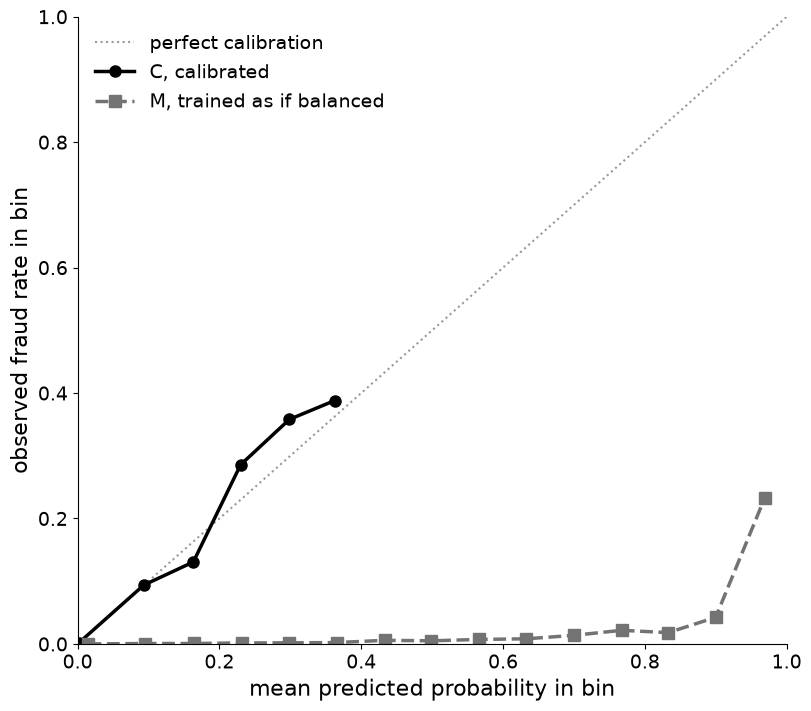

In [6]:
MIN_BIN = 50


def reliability(y, p, bins=15):
    # Same bins as ECE; bins with fewer than MIN_BIN transactions are not drawn.
    b = bin_index(p, bins)
    n = np.bincount(b, minlength=bins)
    keep = n >= MIN_BIN
    return np.bincount(b, p, bins)[keep] / n[keep], np.bincount(b, y, bins)[keep] / n[keep]


fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
ax.plot([0, 1], [0, 1], ":", color="0.6", lw=1.5, label="perfect calibration")
for m, style, label in [("C", dict(color="black", ls="-", marker="o"), "C, calibrated"),
                        ("M", dict(color="0.45", ls="--", marker="s"), "M, trained as if balanced")]:
    ax.plot(*reliability(yF, probs2[m]), lw=2.5, ms=8, label=label, **style)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="mean predicted probability in bin",
       ylabel="observed fraud rate in bin")
ax.legend(loc="upper left")
save(fig, "reliability")

## 3. A working point: precision is low, and that can still be right

**Decision:** set a threshold and send every transaction above it to review.

**What the model must provide:** a working point where the review queue pays for itself.

**What answers it:** profit at the working point, and precision and recall read against the cost
ratio. **What misleads:** ROC AUC, which averages over false positive rates that, at a 0.5% base
rate, mean thousands of reviews; and F1, which has no $V$ or $c$ in it.

The fraud model from the top of the notebook (0.5%, ROC AUC 0.97).

In [7]:
RECALLS = [0.5, 0.7, 0.8, 0.9]
wp = pd.DataFrame([at_recall(r, tprF, fprF, nF) for r in RECALLS], index=RECALLS)
wp_sim = pd.DataFrame([sim_at_recall(yF, sF, r) for r in RECALLS], index=RECALLS)
print("Analytic vs simulated:")
report("s3_working_points_sim_check",
       pd.DataFrame({"reviews": wp["reviews"], "reviews sim": wp_sim["reviews"],
                     "precision": wp["precision"], "precision sim": wp_sim["precision"],
                     "profit": wp["profit"], "profit sim": wp_sim["profit"]}),
       {"reviews": 0, "reviews sim": 0, "precision": 3, "precision sim": 3, "profit": 0, "profit sim": 0})
print()

best3, prauc3 = pr_summary(tprF, fprF, nF)
top3 = max_profit(dF, nF)
prec3 = point(GRID, tprF, fprF, nF)["precision"]  # for the figures
special = pd.DataFrame({"best F1": best3, "max profit": top3,
                        "best F1 sim": sim_best_f1(yF, sF),
                        "max profit sim": sim_max_profit(yF, sF, dF)}).T
# F1's best threshold is always p = F1 / 2, so it implies a cost ratio set by the model.
p_f1 = posterior(solve(tprF, best3["recall"]), dF, RATE)
print(f"Best-F1 threshold on the posterior: {p_f1:.4f}; best F1 / 2 = {best3['F1'] / 2:.4f}; "
      f"the V / c that would make it optimal: {1 / p_f1:.1f} (here V / c = {V // COST})")
equal = point(score_at_posterior(0.5, dF, RATE), tprF, fprF, nF)
print(f"Equal error costs (p > 0.5): {equal['reviews']:.0f} reviews, recall {equal['recall']:.2f}, "
      f"F1 {equal['F1']:.2f}")
prauc3_sim = average_precision_score(yF, sF)
print(f"PR AUC: {prauc3:.3f} | sim {prauc3_sim:.3f}\n")

check("S3 best-F1 threshold = best F1 / 2", p_f1, best3["F1"] / 2, "close")
RESULTS["s3_f1_threshold"] = {"best-F1 threshold": round(p_f1, 4), "implied V / c": round(1 / p_f1, 1),
                              "equal costs: reviews": round(equal["reviews"]),
                              "equal costs: recall": round(equal["recall"], 2),
                              "equal costs: F1": round(equal["F1"], 2)}
for r, reviews, prec, profit in [(0.5, 639, 0.391, 46805), (0.7, 1978, 0.177, 60110),
                                 (0.8, 3834, 0.104, 60829), (0.9, 8814, 0.051, 45932)]:
    check(f"S3 recall {r:.0%}: reviews", wp.loc[r, "reviews"], reviews, "count")
    check(f"S3 recall {r:.0%}: precision", wp.loc[r, "precision"], prec, "rate")
    check(f"S3 recall {r:.0%}: profit", wp.loc[r, "profit"], profit, "count")
check("S3 best F1", best3["F1"], 0.46, "rate")
check("S3 best F1: recall", best3["recall"], 0.42, "rate")
check("S3 best F1: precision", best3["precision"], 0.50, "rate")
check("S3 max profit: recall", top3["recall"], 0.76, "rate")
check("S3 max profit: precision", top3["precision"], 0.13, "rate")
check("S3 max profit: reviews", top3["reviews"], 2972, "count")
check("S3 max profit: profit", top3["profit"], 61479, "count")
check("S3 PR AUC", prauc3, 0.44, "rate")

report("s3_working_points", wp, POINT_DIGITS)
print()
report("s3_best_f1_and_max_profit", special, POINT_DIGITS)
RESULTS["s3_pr_auc"] = {"analytic": round(prauc3, 2), "sim": round(prauc3_sim, 2)}

Analytic vs simulated:
     reviews  reviews sim  precision  precision sim  profit  profit sim
0.5      639          649      0.391          0.385   46805       46755
0.7     1978         1807      0.177          0.194   60110       60965
0.8     3834         3995      0.104          0.100   60829       60025
0.9     8814         8416      0.051          0.053   45932       47920



Best-F1 threshold on the posterior: 0.2283; best F1 / 2 = 0.2284; the V / c that would make it optimal: 4.4 (here V / c = 40)
Equal error costs (p > 0.5): 172 reviews, recall 0.25, F1 0.38
PR AUC: 0.444 | sim 0.417

     recall     FPR  caught  false alarms  reviews  precision    F1  profit
0.5     0.5  0.0039     250           389      639      0.391  0.44   46805
0.7     0.7  0.0164     350          1628     1978      0.177  0.28   60110
0.8     0.8  0.0345     400          3434     3834      0.104  0.18   60829
0.9     0.9  0.0841     450          8364     8814      0.051  0.10   45932

                recall     FPR  caught  false alarms  reviews  precision    F1  profit
best F1           0.42  0.0021     210           209      419      0.501  0.46   39886
max profit        0.76  0.0260     382          2590     2972      0.128  0.22   61479
best F1 sim       0.45  0.0025     225           247      472      0.477  0.46   42640
max profit sim    0.76  0.0267     382          2653   

**F1 is low here, and the model still makes money.** At the profit-maximizing point fewer than one
review in seven finds a fraud, and that point earns more than the best-F1 point. A stopped fraud is
worth $V / c = 40$ reviews. Whether a working point is usable depends on that cost ratio, and the
profit-maximizing point is set by $p > c / V = 1/40$, not by F1. On calibrated probabilities the
best-F1 threshold is $p = F1^* / 2$, where $F1^*$ is the best F1 (Lipton, Elkan and Narayanaswamy,
2014, "Thresholding classifiers to maximize F1 score"), so maximizing F1 assumes a cost ratio
$V / c = 2 / F1^*$, about 4.4 here, a number that comes from the model alone. Nor does F1 stand for
equal costs: those give the rule $p > 0.5$, printed above the table.

**The average fraudster.** ROC AUC is the probability that a random fraud scores above a random
legitimate transaction, so $1 - \text{ROC AUC}$ is the expected share of legitimate transactions
scored above a random fraud. With 99,500 legitimate transactions that is
$0.03 \times 99{,}500 = 2{,}985$ ahead of the average fraudster in the queue. The distribution is
skewed: the median fraudster scores $d$, so only about $99{,}500 \times (1 - \Phi(d))$ legitimate
transactions are ahead of them. In the simulation the mean is exactly
$(1 - \text{simulated ROC AUC}) \times 99{,}500$, so it moves with the simulated ROC AUC.

In [8]:
neg_sorted = np.sort(sF[yF == 0])
ahead = len(neg_sorted) - np.searchsorted(neg_sorted, sF[yF == 1])
fraudster = pd.DataFrame({"analytic": [(1 - AUC) * nF_neg, nF_neg * norm.sf(dF)],
                          "sim": [ahead.mean(), np.median(ahead)]},
                         index=["mean legitimate ahead", "median legitimate ahead"])
check("S3 mean legitimate ahead of a fraudster", fraudster.loc["mean legitimate ahead", "analytic"],
      2985, "count")
check("S3 median legitimate ahead of a fraudster", fraudster.loc["median legitimate ahead", "analytic"],
      389, "count")
check("S3 simulated mean ahead = (1 - simulated ROC AUC) x legitimate", ahead.mean(),
      (1 - roc_auc_score(yF, sF)) * nF_neg, "exact")
report("s3_average_fraudster", fraudster, {"analytic": 0, "sim": 0})

                         analytic   sim
mean legitimate ahead        2985  2737
median legitimate ahead       389   402


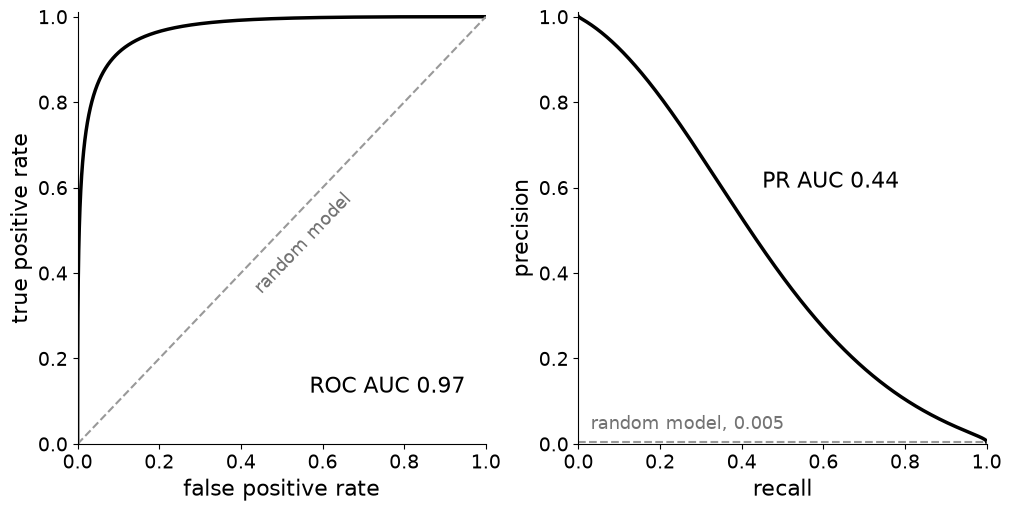

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), layout="constrained")
ax1.plot(fprF(GRID), tprF(GRID), color="black", lw=2.5)
ax1.plot([0, 1], [0, 1], "--", color="0.6", lw=1.5)
ax1.text(0.45, 0.35, "random model", color="0.45", rotation=45, rotation_mode="anchor",
         transform_rotates_text=True, fontsize=13)
ax1.text(0.95, 0.12, f"ROC AUC {AUC:.2f}", ha="right", fontsize=16)
ax1.set(xlim=(0, 1), ylim=(0, 1.01), xlabel="false positive rate", ylabel="true positive rate")

ax2.plot(tprF(GRID), prec3, color="black", lw=2.5)
ax2.axhline(RATE, ls="--", color="0.6", lw=1.5)
ax2.text(0.03, RATE + 0.03, f"random model, {RATE}", color="0.45", fontsize=13)
ax2.text(0.45, 0.6, f"PR AUC {prauc3:.2f}", fontsize=16)
ax2.set(xlim=(0, 1), ylim=(0, 1.01), xlabel="recall", ylabel="precision")
save(fig, "roc_pr")

## 4. Same ROC curve, different base rate

**Decision:** the same as in Section 3, a review threshold, now for two fraud types scored by the
same model with the same $V$ and $c$: type 1 at 2% of transactions and type 2 at 0.2%.

**What the model must provide:** a working point that pays for itself, for each type.

**What answers it:** precision and profit at the working point, and PR AUC read against its random
baseline (the base rate). **What misleads:** ROC AUC, which is the same for both types because the
ROC curve does not depend on the base rate; and PR AUC compared across types without that
baseline.

Both types get the same score distributions (ROC AUC 0.97), so at recall 70% they share the
threshold and the false positive rate. With a 40 to 1 ratio between $V$ and $c$ the model earns
money on both; precision falls sharply with the base rate, profit per fraud far less. The last
table repeats type 2 with $c = 40$, a 5 to 1 ratio: at recall 70% it then loses money, and its best
threshold still earns a little only by reviewing the very top of the list.

In [10]:
TYPES = {"type 1": 0.02, "type 2": 0.002}
rows, sims, curves4 = {}, {}, {}
for ft, rate in TYPES.items():
    n = round(rate * N)
    y, s = simulate_binormal(n, dF)
    a = at_recall(0.7, tprF, fprF, n)
    top = max_profit(dF, n)
    best, prauc = pr_summary(tprF, fprF, n)
    rows[ft] = {"reviews at recall 70%": a["reviews"], "precision at recall 70%": a["precision"],
                "profit at recall 70%": a["profit"], "max profit: recall": top["recall"],
                "max profit: precision": top["precision"], "max profit: reviews": top["reviews"],
                "max profit": top["profit"], "profit per fraud at recall 70%": a["profit"] / n,
                "max profit per fraud": top["profit"] / n, "best F1": best["F1"], "best F1: recall": best["recall"],
                "best F1: precision": best["precision"], "PR AUC": prauc, "PR AUC random": rate}
    b, bp = sim_at_recall(y, s, 0.7), sim_max_profit(y, s, dF)
    sims[ft] = {"reviews at recall 70% sim": b["reviews"], "profit at recall 70% sim": b["profit"],
                "max profit sim": bp["profit"], "best F1 sim": sim_best_f1(y, s)["F1"],
                "PR AUC sim": average_precision_score(y, s)}
    curves4[ft] = point(GRID, tprF, fprF, n)["precision"]
tab4 = pd.DataFrame(rows).T
print("Simulated check:")
report("s4_sim_check", pd.DataFrame(sims).T,
       {"reviews at recall 70% sim": 0, "profit at recall 70% sim": 0, "max profit sim": 0,
        "best F1 sim": 3, "PR AUC sim": 3})
print()

for ft, reviews, prec, profit, top_r, top_p, top_profit, prauc in [
        ("type 1", 3004, 0.466, 264982, 0.89, 0.189, 309946, 0.65),
        ("type 2", 1773, 0.079, 19135, 0.64, 0.105, 19632, 0.32)]:
    check(f"S4 {ft}: reviews at recall 70%", tab4.loc[ft, "reviews at recall 70%"], reviews, "count")
    check(f"S4 {ft}: precision at recall 70%", tab4.loc[ft, "precision at recall 70%"], prec, "rate")
    check(f"S4 {ft}: profit at recall 70%", tab4.loc[ft, "profit at recall 70%"], profit, "count")
    check(f"S4 {ft}: max profit recall", tab4.loc[ft, "max profit: recall"], top_r, "rate")
    check(f"S4 {ft}: max profit precision", tab4.loc[ft, "max profit: precision"], top_p, "rate")
    check(f"S4 {ft}: max profit", tab4.loc[ft, "max profit"], top_profit, "count")
    check(f"S4 {ft}: PR AUC", tab4.loc[ft, "PR AUC"], prauc, "rate")

report("s4_base_rate", tab4,
       {"reviews at recall 70%": 0, "precision at recall 70%": 3, "profit at recall 70%": 0,
        "max profit: recall": 2, "max profit: precision": 3, "max profit: reviews": 0,
        "max profit": 0, "profit per fraud at recall 70%": 0, "max profit per fraud": 0, "best F1": 2, "best F1: recall": 2, "best F1: precision": 2,
        "PR AUC": 2, "PR AUC random": 3})

COST_HIGH = 40
n2 = round(TYPES["type 2"] * N)
high = pd.DataFrame({"recall 70%": at_recall(0.7, tprF, fprF, n2, COST_HIGH),
                     "max profit": max_profit(dF, n2, COST_HIGH)}).T
check("S4 type 2 with c = 40 loses money at recall 70%", int(high.loc["recall 70%", "profit"] < 0), 1, "exact")
print(f"\nType 2 with c = {COST_HIGH} (V / c = {V // COST_HIGH}):")
report("s4_type2_cost_40", high, POINT_DIGITS)

Simulated check:
        reviews at recall 70% sim  profit at recall 70% sim  max profit sim  best F1 sim  PR AUC sim
type 1                       3147                    264265          308955        0.592       0.625
type 2                       1669                     19655           19620        0.350       0.293

        reviews at recall 70%  precision at recall 70%  profit at recall 70%  max profit: recall  max profit: precision  max profit: reviews  max profit  profit per fraud at recall 70%  max profit per fraud  best F1  best F1: recall  best F1: precision  PR AUC  PR AUC random
type 1                   3004                    0.466                264982                0.89                  0.189                 9472      309946                             132                   155     0.60             0.57                0.64    0.65          0.020
type 2                   1773                    0.079                 19135                0.64                  0.105        

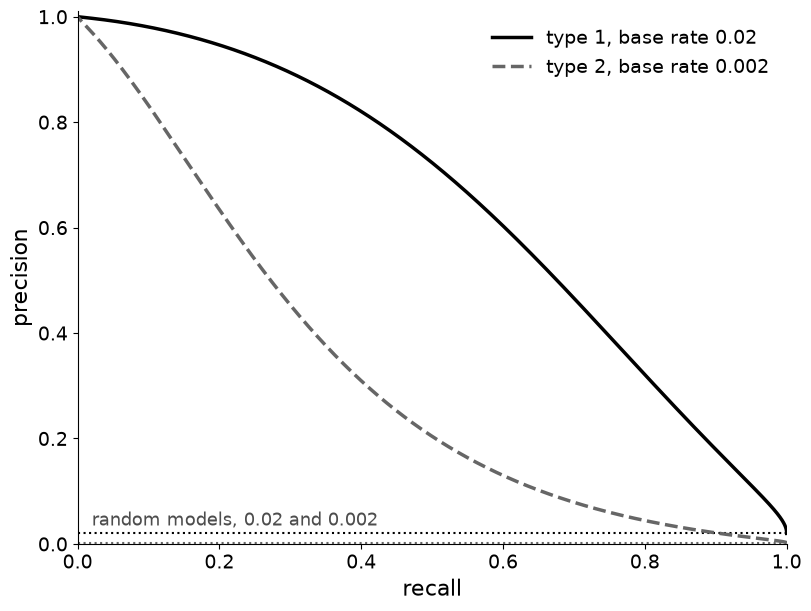

In [11]:
fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
for (ft, rate), style in zip(TYPES.items(), [dict(color="black", ls="-"), dict(color="0.4", ls="--")]):
    ax.plot(tprF(GRID), curves4[ft], lw=2.5, label=f"{ft}, base rate {rate}", **style)
    ax.axhline(rate, color=style["color"], ls=":", lw=1.5)
# Both base rates sit in the bottom 2% of the axis: one label for the pair of random-model lines.
ax.text(0.02, max(TYPES.values()) + 0.015, "random models, " + " and ".join(map(str, TYPES.values())),
        color="0.3", fontsize=13)
ax.set(xlim=(0, 1), ylim=(0, 1.01), xlabel="recall", ylabel="precision")
ax.legend(loc="upper right")
save(fig, "pr_base_rate")

## 5. Top-k: fixed analyst capacity

**Decision:** the analysts can review $k = 450$ transactions a day; send them the 450 at the top of
the list.

**What the model must provide:** the right order at the very top of the list. What happens further
down does not matter.

**What answers it:** precision@k, frauds caught@k and profit@k. **What misleads:** ROC AUC, which
gives every legitimate transaction the same weight wherever it sits in the list.

Fraud 0.5% (500 frauds). In **model A** 90% of the frauds (450) score $N(5, 1)$ and are easy to
find; the other 10% score $N(0, 1)$, like the legitimate transactions, and the model cannot see
them at all. **Model B** is binormal, with $d$ chosen so that its analytic ROC AUC equals A's
analytic ROC AUC. Budgets of 250 and 900 are reported too, to show the conclusion does not depend on
a capacity picked to suit A.

In [12]:
K, SHARE_HI = 450, 0.9
n_hi = round(SHARE_HI * nF)
yA = np.r_[np.ones(nF, dtype=int), np.zeros(N - nF, dtype=int)]
sA = np.r_[rng.normal(5, 1, n_hi), rng.normal(0, 1, N - n_hi)]
aucA = SHARE_HI * norm.cdf(5 / np.sqrt(2)) + (1 - SHARE_HI) * 0.5
dB = d_for_auc(aucA)
yB, sB = simulate_binormal(nF, dB)

MODELS5 = {"A": (yA, sA, lambda t: SHARE_HI * norm.sf(t - 5) + (1 - SHARE_HI) * norm.sf(t), norm.sf),
           "B": (yB, sB, *binormal(dB))}
BUDGETS5 = [250, K, 900]

rank_rows, top_rows = {}, {}
for m, (y, s, tpr, fpr) in MODELS5.items():
    rank_rows[m] = {"ROC AUC": aucA, "ROC AUC sim": roc_auc_score(y, s),
                    "PR AUC": pr_summary(tpr, fpr, nF)[1], "PR AUC sim": average_precision_score(y, s)}
    tp_sim = sim_top(y, s)
    for k in BUDGETS5:
        a = at_reviews(k, tpr, fpr, nF)
        top_rows[f"{m}, k = {k}"] = {"precision": a["precision"], "caught": a["caught"],
                                     "profit": a["profit"], "precision sim": tp_sim[k - 1] / k,
                                     "caught sim": tp_sim[k - 1], "profit sim": V * tp_sim[k - 1] - COST * k}
tab5_rank, tab5_top = pd.DataFrame(rank_rows).T, pd.DataFrame(top_rows).T

check("S5 analytic ROC AUC of A and B", aucA, 0.95, "rate")
for m in "AB":
    check(f"S5 {m}: simulated ROC AUC", tab5_rank.loc[m, "ROC AUC sim"], 0.95, "rate")
for row, prec in [("A, k = 450", 0.939), ("B, k = 450", 0.367)]:
    check(f"S5 {row}: precision", tab5_top.loc[row, "precision"], prec, "rate")
for row, caught, profit in [("A, k = 450", 423, 82257), ("B, k = 450", 165, 30770),
                            ("A, k = 250", 250, 48738), ("B, k = 250", 122, 23208),
                            ("A, k = 900", 446, 84792), ("B, k = 900", 222, 39814)]:
    check(f"S5 {row}: caught", tab5_top.loc[row, "caught"], caught, "count")
    check(f"S5 {row}: profit", tab5_top.loc[row, "profit"], profit, "count")

report("s5_ranking", tab5_rank, {c: 3 for c in tab5_rank.columns})
print()
report("s5_top_k", tab5_top, {"precision": 3, "caught": 0, "profit": 0,
                              "precision sim": 3, "caught sim": 0, "profit sim": 0})

   ROC AUC  ROC AUC sim  PR AUC  PR AUC sim
A     0.95        0.951   0.886       0.883
B     0.95        0.950   0.301       0.293

            precision  caught  profit  precision sim  caught sim  profit sim
A, k = 250      1.000     250   48738          1.000         250       48750
A, k = 450      0.939     423   82257          0.933         420       81750
A, k = 900      0.496     446   84792          0.492         443       84100
B, k = 250      0.489     122   23208          0.472         118       22350
B, k = 450      0.367     165   30770          0.364         164       30550
B, k = 900      0.246     222   39814          0.247         222       39900


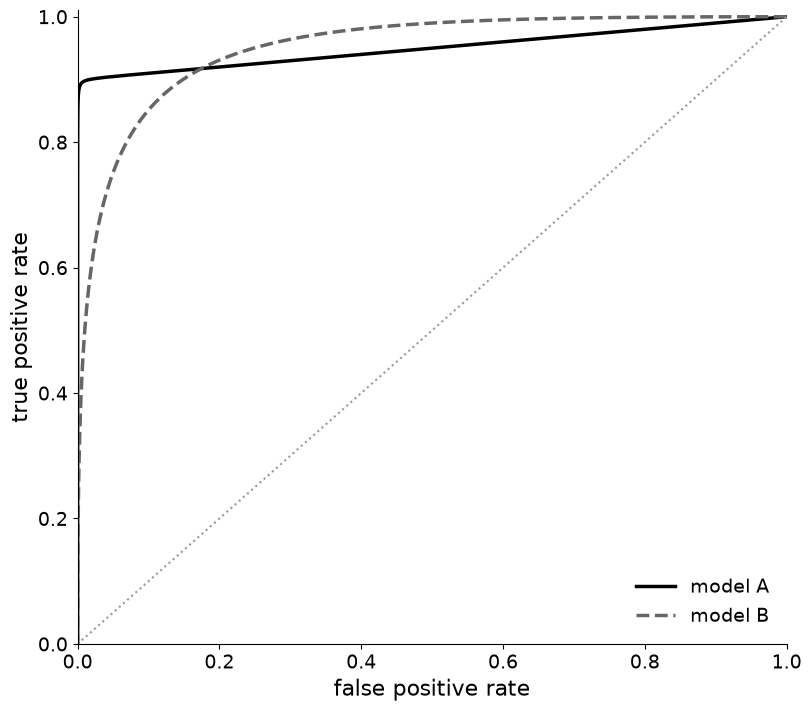

In [13]:
fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
for (m, (_, _, tpr, fpr)), style in zip(MODELS5.items(), [dict(color="black", ls="-"),
                                                          dict(color="0.4", ls="--")]):
    ax.plot(fpr(GRID), tpr(GRID), lw=2.5, label=f"model {m}", **style)
ax.plot([0, 1], [0, 1], ":", color="0.6", lw=1.5)
ax.set(xlim=(0, 1), ylim=(0, 1.01), xlabel="false positive rate", ylabel="true positive rate")
ax.legend(loc="lower right")
save(fig, "roc_crossing")

## 6. A constraint on one error (Neyman-Pearson)

**Decision:** a hard limit on one type of error, and the best possible rate of the other within it.
Two versions, with models A and B from Section 5:

- **Customer-friction rule:** block at most 0.1% of legitimate transactions (FPR at most 0.1%);
  catch as much fraud as possible.
- **Insurer rule:** catch at least 95% of fraud (recall at least 95%); flag as few legitimate
  transactions as possible.

**What the model must provide:** a good rate of the free error at the constrained point.

**What answers it:** for the friction rule, TPR at the fixed FPR and partial ROC AUC over a low FPR
range ($[0, 0.05]$ here, wider than the 0.1% rule allows); for the insurer rule, precision and FPR
at the recall floor. **What misleads:** full ROC AUC, which is the same for A and B, while the
better model flips between the two rules.

Partial ROC AUC is `roc_auc_score(..., max_fpr=0.05)`. scikit-learn returns the McClish-standardized
value, which maps the area over FPR in $[0, 0.05]$ to a scale where 0.5 is a random model and 1 a
perfect one.

In [14]:
FPR_MAX, RECALL_MIN, PAUC_FPR = 0.001, 0.95, 0.05
u = np.linspace(0, PAUC_FPR, 100_001)


def mcclish(area, max_fpr=PAUC_FPR):
    return 0.5 * (1 + (area - max_fpr**2 / 2) / (max_fpr - max_fpr**2 / 2))


rows = {}
for m, (y, s, tpr, fpr) in MODELS5.items():
    t_sim = np.quantile(s[y == 0], 1 - FPR_MAX, method="higher")  # at most 0.1% above it
    a = at_recall(RECALL_MIN, tpr, fpr, nF)
    b = sim_at_recall(y, s, RECALL_MIN)
    rows[m] = {"TPR at FPR 0.1%": tpr(norm.isf(FPR_MAX)),
               "TPR at FPR 0.1% sim": np.mean(s[y == 1] > t_sim),
               "precision at recall 95%": a["precision"], "precision at recall 95% sim": b["precision"],
               "FPR at recall 95%": a["FPR"], "FPR at recall 95% sim": b["FPR"],
               "partial ROC AUC": mcclish(np.trapezoid(tpr(norm.isf(u)), u)),
               "partial ROC AUC sim": roc_auc_score(y, s, max_fpr=PAUC_FPR)}
tab6 = pd.DataFrame(rows).T
check("S6 A beats B at FPR 0.1%", int(tab6.loc["A", "TPR at FPR 0.1%"] > tab6.loc["B", "TPR at FPR 0.1%"]), 1, "exact")
check("S6 B beats A at recall 95%",
      int(tab6.loc["B", "precision at recall 95%"] > tab6.loc["A", "precision at recall 95%"]), 1, "exact")
report("s6_constraint", tab6, {c: 4 if "precision" in c else 3 for c in rows["A"]})

   TPR at FPR 0.1%  TPR at FPR 0.1% sim  precision at recall 95%  precision at recall 95% sim  FPR at recall 95%  FPR at recall 95% sim  partial ROC AUC  partial ROC AUC sim
A            0.875                0.874                   0.0095                       0.0093              0.500                  0.509            0.948                0.948
B            0.222                0.220                   0.0188                       0.0197              0.249                  0.238            0.795                0.796


## 7. Zones with manual review

**Decision:** pass automatically below $t_{low}$, send to an analyst between $t_{low}$ and
$t_{high}$, block automatically above $t_{high}$. Analysts are expensive, so the question is how
many transactions they must see to keep the automatic decisions under a target error rate of 0.1%.

**What the model must provide:** calibrated probabilities, so that "how uncertain is this case" can
be read off the score.

**What answers it:** the risk-coverage curve: the share sent to review against the error rate in the
automatic zones. **What misleads:** ROC AUC and PR AUC, which summarize the whole ranking and say
nothing about how many transactions one band of it holds or how often that band errs.

The fraud model from the top of the notebook with calibrated probabilities. Unlike the profit
framing of Sections 2 to 6, this section counts a blocked legitimate transaction and a fraud passed
automatically as the same error, so an automatic decision blocks when $p > 0.5$. For a given review
share, the fewest expected errors remain when the reviewed transactions are those with $p$ closest
to 0.5, which makes the review zone an interval $[t_{low}, 1 - t_{low}]$ around 0.5. The analytic
curve sweeps $t_{low}$; the simulated one sends transactions to review one at a time, least certain
first.

In transactions, the 0.1% target means that almost all of the error budget is frauds passed, about a fifth of the day's
fraud goes through unreviewed, and the few transactions blocked are nearly all fraud.

In [15]:
ERR_TARGET = 0.001

# Simulation: errors left in the automatic zones after reviewing the k least certain transactions.
err = np.where(pF > 0.5, 1 - yF, yF)
order = np.argsort(-np.minimum(pF, 1 - pF))
k = np.arange(N)
risk_sim = (err.sum() - np.r_[0, np.cumsum(err[order])][:-1]) / (N - k)
share_sim = k / N


def zone(t_low):
    a, b = score_at_posterior(t_low, dF, RATE), score_at_posterior(1 - t_low, dF, RATE)
    review = nF * (norm.cdf(b - dF) - norm.cdf(a - dF)) + nF_neg * (norm.cdf(b) - norm.cdf(a))
    errors = nF * norm.cdf(a - dF) + nF_neg * norm.sf(b)
    return review / N, errors / (N - review)


t_lows = np.geomspace(1e-6, 0.5, 500)
share_an, risk_an = zone(t_lows)
t_star = brentq(lambda t: zone(t)[1] - ERR_TARGET, 1e-6, 0.5)
share_star, risk_star = zone(t_star)
i = np.argmax(risk_sim < ERR_TARGET)
p_i = pF[order[i - 1]]

tab7 = pd.DataFrame({
    "analytic": {"error rate, no review": zone(0.5)[1], "review share": share_star,
                 "t_low": t_star, "t_high": 1 - t_star, "error rate": risk_star},
    "sim": {"error rate, no review": risk_sim[0], "review share": share_sim[i],
            "t_low": min(p_i, 1 - p_i), "t_high": max(p_i, 1 - p_i), "error rate": risk_sim[i]}})
lo, hi = score_at_posterior(t_star, dF, RATE), score_at_posterior(1 - t_star, dF, RATE)
zone_counts = pd.DataFrame({"analytic": {"frauds passed": nF * norm.cdf(lo - dF),
                                         "reviewed": share_star * N,
                                         "blocked": nF * norm.sf(hi - dF) + nF_neg * norm.sf(hi)}})
check("S7 transactions reviewed for a 0.1% error rate", share_star * N, 4064, "count")
print(f"Review share needed for an automatic-zone error rate under {ERR_TARGET:.1%}:\n")
report("s7_review_zones", tab7, {"analytic": 4, "sim": 4})
print()
report("s7_zone_counts", zone_counts, {"analytic": 0})

Review share needed for an automatic-zone error rate under 0.1%:

                       analytic     sim
error rate, no review    0.0042  0.0043
review share             0.0406  0.0422
t_low                    0.0167  0.0165
t_high                   0.9833  0.9835
error rate               0.0010  0.0010

               analytic
frauds passed        96
reviewed           4064
blocked               7


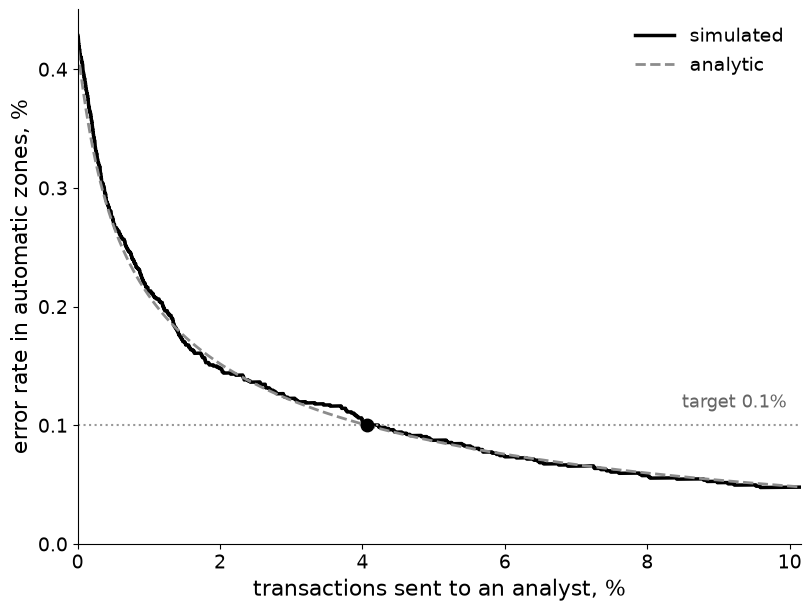

In [16]:
X_MAX7 = 100 * 2.5 * share_star
fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
ax.plot(100 * share_sim, 100 * risk_sim, color="black", lw=2.5, label="simulated")
ax.plot(100 * share_an, 100 * risk_an, "--", color="0.55", lw=2, label="analytic")
ax.axhline(100 * ERR_TARGET, color="0.6", ls=":", lw=1.5)
ax.plot(100 * share_star, 100 * ERR_TARGET, "o", color="black", ms=9)
ax.text(0.98 * X_MAX7, 100 * ERR_TARGET * 1.15, f"target {ERR_TARGET:.1%}", ha="right", color="0.4",
        fontsize=13)
ax.set(xlim=(0, X_MAX7), ylim=(0, None),
       xlabel="transactions sent to an analyst, %", ylabel="error rate in automatic zones, %")
ax.legend(loc="upper right")
save(fig, "risk_coverage")

## 8. The effect of the action: uplift

This section switches domain. Fraud review has no natural treatment effect: a review stops a fraud
or it does not. The example here is customer retention, where a call can change whether a customer
leaves, and for some customers in the wrong direction.

**Decision:** whom to call, when the call changes the outcome.

**What the model must provide:** the effect of the call on each customer: churn probability without
a call minus churn probability with one.

**What answers it:** uplift metrics: the Qini curve and the area under the uplift curve (AUUC).
**What misleads:** churn-prediction metrics. They score how well the model predicts churn without
a call, which is the right question for a churn model and the wrong one here. A churn model with the
highest ROC AUC and the lowest Brier any model can expect on these customers ranks by risk, not by
the effect of the call.

The segments are made up for illustration:

| segment | customers | churn without a call | churn with a call |
|---|---|---|---|
| lost causes | 1,000 | 70% | 70% |
| persuadables | 1,000 | 40% | 10% |
| sleeping dogs | 1,000 | 15% | 35% |
| everybody else | 97,000 | 0.5% | 0.5% |

Two targeting rules. The **churn model** is perfectly calibrated and knows each customer's churn
probability without a call exactly; it calls the highest first. The **uplift model** calls in order
of the true reduction in churn from a call. Customers saved is the expected number: the sum of the
reductions over the called customers. A call to a sleeping dog counts as -0.2, so the total falls
once the list reaches them.

In [17]:
seg = pd.DataFrame({"customers": [1000, 1000, 1000, 97_000],
                    "churn no call": [0.70, 0.40, 0.15, 0.005],
                    "churn call": [0.70, 0.10, 0.35, 0.005]},
                   index=["lost causes", "persuadables", "sleeping dogs", "everybody else"])
p0 = np.repeat(seg["churn no call"].to_numpy(), seg["customers"])
uplift = p0 - np.repeat(seg["churn call"].to_numpy(), seg["customers"])
RULES = {"churn model": np.argsort(-p0, kind="stable"),
         "uplift model": np.argsort(-uplift, kind="stable")}
saved = {r: np.r_[0, np.cumsum(uplift[o])] for r, o in RULES.items()}
BUDGETS = [1000, 2000, 3000]

y0 = (rng.random(N) < p0).astype(int)
check("S8 churn model saves nobody at 1,000 calls", saved["churn model"][1000], 0.0, "exact")

report("s8_uplift", pd.DataFrame({r: {f"saved at {b:,} calls": v[b] for b in BUDGETS}
                                  for r, v in saved.items()}).T,
       {f"saved at {b:,} calls": 0 for b in BUDGETS})
print("\nChurn model against simulated no-call outcomes. The true probabilities give the lowest")
print("expected Brier and the highest expected ROC AUC any model can reach on these customers:")
report("s8_churn_model_metrics",
       pd.DataFrame({"churn model": {"ROC AUC": roc_auc_score(y0, p0), "Brier": brier_score_loss(y0, p0),
                                     "expected Brier": np.mean(p0 * (1 - p0))}}).T,
       {"ROC AUC": 3, "Brier": 4, "expected Brier": 4})

              saved at 1,000 calls  saved at 2,000 calls  saved at 3,000 calls
churn model                      0                   300                   100
uplift model                   300                   300                   300

Churn model against simulated no-call outcomes. The true probabilities give the lowest
expected Brier and the highest expected ROC AUC any model can reach on these customers:
             ROC AUC   Brier  expected Brier
churn model    0.851  0.0107          0.0106


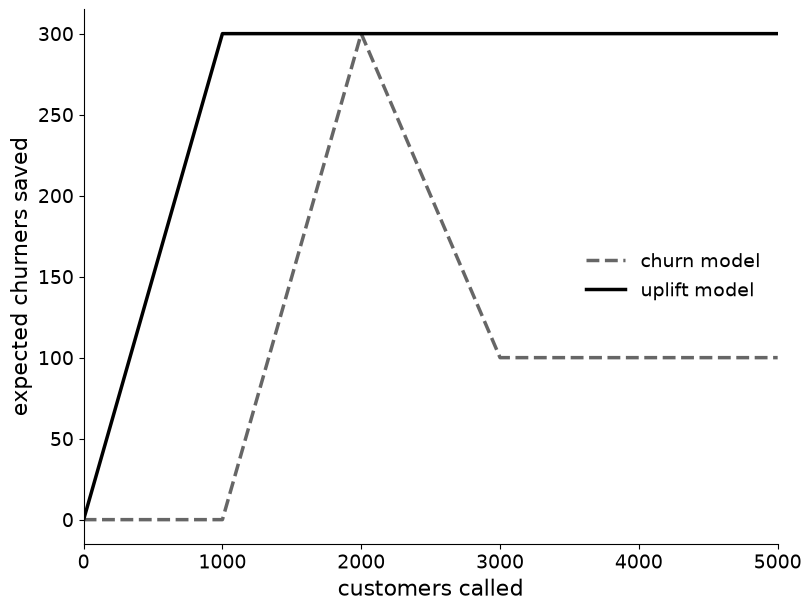

In [18]:
X_MAX = 5000
fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
for (r, v), style in zip(saved.items(), [dict(color="0.4", ls="--"), dict(color="black", ls="-")]):
    ax.plot(np.arange(X_MAX + 1), v[:X_MAX + 1], lw=2.5, label=r, **style)
ax.set(xlim=(0, X_MAX), xlabel="customers called", ylabel="expected churners saved")
ax.legend(loc="center right")
save(fig, "qini")

## 9. Ranking over the whole range

**Decision:** the order of the day's alert queue (the transactions a rule engine has already
flagged), which analysts work from the top down without knowing in advance how far they will get.
That depends on the day's staffing, sick leave and how long each case takes: some days they clear
the top few hundred alerts, other days nearly the whole queue, and no single threshold or $k$
describes the work.

**What the model must provide:** fraud ranked ahead of legitimate alerts everywhere in the queue,
not only at one threshold or at the top.

**What answers it:** ROC AUC on the alert queue. It is the probability that a random fraud is
ranked above a random legitimate alert, which is the same as TPR averaged over all false positive
rates, so it fits when the daily cut points are spread over the whole queue.
**What misleads:** a metric at one threshold or at one $k$, which describes only one day of the
queue.

Two caveats. ROC AUC gives every legitimate alert the same weight, so most of it comes from cut
points deep in the queue, where most legitimate alerts sit; if capacity almost always stops near
the top, Section 5 applies instead. And it still says nothing about calibration, which
matters only if the queue is cut by probability rather than by capacity.

## 10. Summary table

Which metric answers which decision, as a figure for the article. The cells are a judgment that sums
up the sections above, not values this notebook computes. Continuous action and conformal sets are
covered in the article only, and Section 9 has no simulation either.

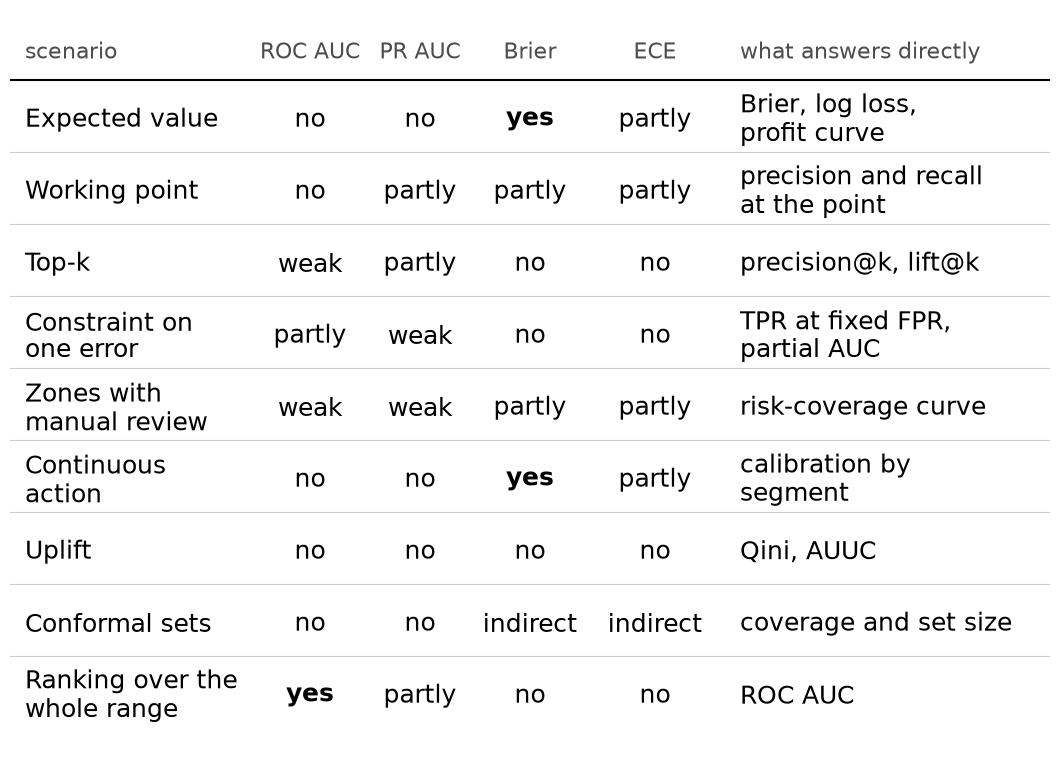

In [19]:
COLS = ["scenario", "ROC AUC", "PR AUC", "Brier", "ECE", "what answers directly"]
TABLE = [
    ("Expected value", "no", "no", "yes", "partly", "Brier, log loss, profit curve"),
    ("Working point", "no", "partly", "partly", "partly", "precision and recall at the point"),
    ("Top-k", "weak", "partly", "no", "no", "precision@k, lift@k"),
    ("Constraint on one error", "partly", "weak", "no", "no", "TPR at fixed FPR, partial AUC"),
    ("Zones with manual review", "weak", "weak", "partly", "partly", "risk-coverage curve"),
    ("Continuous action", "no", "no", "yes", "partly", "calibration by segment"),
    ("Uplift", "no", "no", "no", "no", "Qini, AUUC"),
    ("Conformal sets", "no", "no", "indirect", "indirect", "coverage and set size"),
    ("Ranking over the whole range", "yes", "partly", "no", "no", "ROC AUC"),
]
W, ROW_H, HEAD_H = 10.4, 0.72, 0.6
H = HEAD_H + ROW_H * len(TABLE) + 0.3
X = [0.15, 3.0, 4.1, 5.2, 6.45, 7.3]       # column positions, inches
ALIGN = ["left", "center", "center", "center", "center", "left"]
WRAP = {0: 16, 5: 21}

fig = plt.figure(figsize=(W, H))
ax = fig.add_axes([0, 0, 1, 1], xlim=(0, W), ylim=(H, 0))
ax.axis("off")
for x, col, ha in zip(X, COLS, ALIGN):
    ax.text(x, HEAD_H / 2 + 0.1, col, ha=ha,
            va="center_baseline", fontsize=16, color="0.3")
ax.axhline(HEAD_H + 0.1, color="black", lw=1.5)
for r, row in enumerate(TABLE):
    y = HEAD_H + 0.1 + ROW_H * (r + 0.5)
    for c, (x, val, ha) in enumerate(zip(X, row, ALIGN)):
        ax.text(x, y, textwrap.fill(val, WRAP.get(c, 99)), ha=ha, va="center_baseline", fontsize=18,
                linespacing=1.15, fontweight="bold" if val == "yes" else "normal")
    if r < len(TABLE) - 1:
        ax.axhline(y + ROW_H / 2, color="0.8", lw=0.8)
save(fig, "summary_table")

### Preview image

1500 x 680 px with white margins, for the article preview: the Section 3 ROC and PR curves.

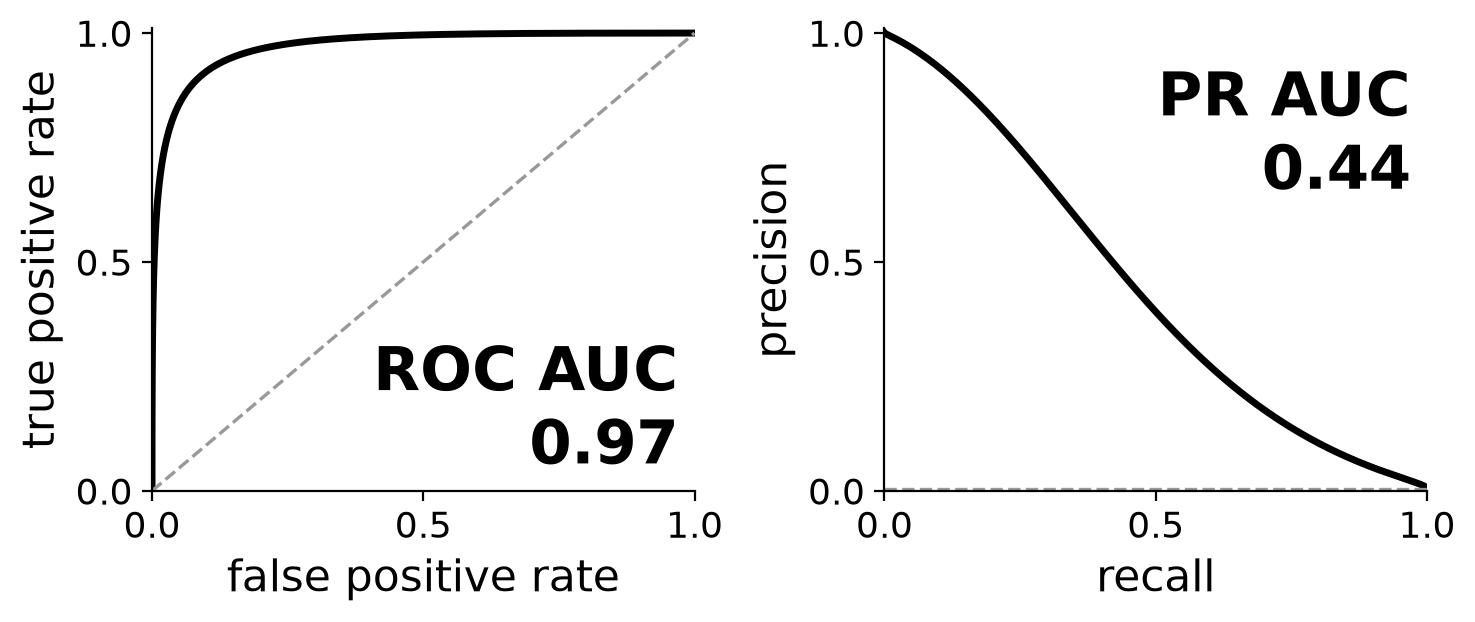

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.5, 3.4), dpi=200)
fig.subplots_adjust(left=0.1, right=0.95, bottom=0.22, top=0.9, wspace=0.35)
ax1.plot(fprF(GRID), tprF(GRID), color="black", lw=2.5)
ax1.plot([0, 1], [0, 1], "--", color="0.6", lw=1.2)
ax1.text(0.97, 0.06, f"ROC AUC\n{AUC:.2f}", ha="right", fontsize=22, fontweight="bold")
ax1.set(xlabel="false positive rate", ylabel="true positive rate")
ax2.plot(tprF(GRID), prec3, color="black", lw=2.5)
ax2.axhline(RATE, ls="--", color="0.6", lw=1.2)
ax2.text(0.97, 0.66, f"PR AUC\n{prauc3:.2f}", ha="right", fontsize=22, fontweight="bold")
ax2.set(xlabel="recall", ylabel="precision")
for ax in (ax1, ax2):
    ax.set(xlim=(0, 1), ylim=(0, 1.01), xticks=[0, 0.5, 1], yticks=[0, 0.5, 1])
    ax.xaxis.label.set_size(16)
    ax.yaxis.label.set_size(16)
    ax.tick_params(labelsize=13)
save(fig, "preview")

## Results and checks

All summary tables go to `classification_metrics_results.json`. The checks compare the computed
values with the values the article states, and the identities the text relies on: counts within 2%
(relative), rates within 0.01 (absolute), the best-F1 threshold within 0.001 of best F1 / 2 (the
grid's resolution), invariances and identities up to float rounding.

In [21]:
Path(f"{PREFIX}results.json").write_text(json.dumps(RESULTS, indent=1, default=lambda o: o.item()))

TOL = {"count": lambda v, e: abs(v - e) <= 0.02 * abs(e),
       "rate": lambda v, e: abs(v - e) <= 0.01,
       "close": lambda v, e: abs(v - e) <= 0.001,
       "exact": lambda v, e: abs(v - e) <= 1e-9 * max(1, abs(e))}
checks = pd.DataFrame(CHECKS)
checks["ok"] = [TOL[k](v, e) for v, e, k in zip(checks["value"], checks["expected"], checks["kind"])]
checks["value"] = checks["value"].map(lambda v: f"{v:.6g}")
print(checks.to_string(index=False), "\n")
failed = checks.loc[~checks["ok"]]
print(f"{checks['ok'].sum()} of {len(checks)} checks matched.")
if len(failed):
    print("Missed tolerance:")
    print(failed[["check", "value", "expected", "kind"]].to_string(index=False))

print("\nSaved figures:")
for f in sorted(Path().glob(f"{PREFIX}*.png")):
    h, w = plt.imread(f).shape[:2]
    print(f"  {f}: {w} x {h} px")

                                                            check       value       expected  kind   ok
                S1 ROC AUC and PR AUC unchanged by p**2 and 0.5*p           0       0.000000 exact True
                                      S1 constant prediction: ECE 3.82215e-15       0.000000 exact True
                                  S1 constant prediction: ROC AUC         0.5       0.500000  rate True
                                 S2 ROC AUC identical for C and M           0       0.000000 exact True
                                  S2 PR AUC identical for C and M           0       0.000000 exact True
S2 transactions selected by only one of M at thr_M and C at 0.025           0       0.000000 exact True
                        S2 M at thr_M: analytic profit equals C's     61479.3   61479.300557 exact True
                                         S2 C, p > 0.025: reviews     2971.64    2972.000000 count True
                                          S2 C, p > 0.025: caugh

In [22]:
print(f"Total runtime: {time.perf_counter() - T0:.1f} s")

Total runtime: 1.8 s
